# Presentación I del proyecto

## EDA de geometrías de ejes viales y dirección de crecimiento urbano

**Insumo:** capa de ejes (cartografía censal MGN, INEC, disponible en https://www.ecuadorencifras.gob.ec/documentos/web-inec/Geografia_Estadistica/Micrositio_geoportal/index.html) sin sentido de circulación ni topología dirigida.

**Pregunta:** ¿es factible, a partir de las geometrías de los ejes, decir sobre qué eje (N–S o E–O) **está orientada** o **se extiende** una ciudad?

| Familia | Qué responde | Herramientas |
|---|---|---|
| **Forma / orientación** de la red | ¿Hacia dónde *apuntan* las calles? | azimut axial, rosa de orientaciones, entropía y orden (Boeing, 2019), componente N–S/E–O |
| **Extensión espacial** de la red  | ¿Hacia dónde *se alarga* la mancha vial? | elipse de desviación estándar, sectores y anillos desde un centro |

**Alcance de análisis:** forma / orientación.

### Entorno
Librerías requeridas: `geopandas>=0.14`, `shapely>=2`, `pyogrio`, `pyarrow`, `matplotlib`, `folium` y `mapclassify`.

In [1]:
#!pip install geopandas shapely pyogrio pyarrow matplotlib folium mapclassify

In [2]:
from pathlib import Path

import numpy as np

import pandas as pd
import geopandas as gpd
import shapely # para trabajar con geometrías planas, motor de gpd
import pyogrio # para lectura en lotes de datos vectoriales, puede usar sql
import matplotlib.pyplot as plt

### 1. Parámetros

In [3]:
RUTA_EJES   = Path("insumos/ejes_l_mgn25.gpkg")   # Colab: Path("/content/drive/MyDrive/.../ejes_l_mgn25.gpkg")
CAPA        = None            # None = primera capa del GPKG
FILTRO_SQL  = "parroquia LIKE '17%'"            # "parroquia LIKE '1701%'"

CAMPO_GRUPO   = "parroquia"   # campo de agrupamiento
MIN_SEGMENTOS = 50            # grupos con menos segmentos no se resumen (entropía sesgada con n pequeño)

N_BINS        = 36            # bins de 10°, como Boeing (2019)
TAM_CELDA     = 1000           # m; malla de agregación (≈1000 m a nivel nacional)

CMAP_AXIAL = "hsv"            # mapa de color cíclico para azimut axial (0° = 180°); alternativa: "twilight"

### 2. Carga
- Descripción del conjunto de datos (sin cargar geometrías)
- Carga de la capa con `pyogrio` + Arrow, que es la vía más rápida para cientos de miles de líneas.
- Se utilizó `FILTRO_SQL` para leer solo una provincia (Pichincha, código 17).

In [4]:
capas = pyogrio.list_layers(RUTA_EJES)
CAPA = CAPA or capas[0][0] # se lee: None or "ejes_l"
info = pyogrio.read_info(RUTA_EJES, layer=CAPA)
print("Conjunto de datos MGN:\n\nCapas:", capas.tolist(), "\n")
print(f"Capa '{CAPA}': {info['features']:,} entidades | {info['geometry_type']} | {info['crs']}\n")
print("Campos:", list(info["fields"]), "\n")
#
gdf = gpd.read_file(RUTA_EJES, layer=CAPA, where=FILTRO_SQL, engine="pyogrio",
                    use_arrow=True, fid_as_index=True) # arrow agiliza la carga por bloques del gdf
#
gdf.head()

Conjunto de datos MGN:

Capas: [['ejes_l', 'MultiLineString']] 

Capa 'ejes_l': 608,882 entidades | MultiLineString | EPSG:31992

Campos: ['fcode', 'parroquia', 'nom_par', 'tipo_eje', 'nom_eje', 'cod_tip_ej', 'fuente', 'anio'] 



,fcode,parroquia,nom_par,tipo_eje,nom_eje,cod_tip_ej,fuente,anio,geometry
fid,,,,,,,,,
23545,BB007,170550,SANGOLQUI,CALLE,Q,CL.,CPV2021,2021,"MULTILINESTRING ((785098.881 9958937.634, 7850..."
23546,BB007,170550,SANGOLQUI,CALLE,Q,CL.,CPV2021,2021,"MULTILINESTRING ((785145.263 9958939.383, 7851..."
23547,BB007,170550,SANGOLQUI,CALLE,3,CL.,CPV2021,2021,"MULTILINESTRING ((785096.234 9959042.471, 7850..."
23548,BB007,170550,SANGOLQUI,CALLE,P,CL.,CPV2021,2021,"MULTILINESTRING ((785011.619 9959048.439, 7850..."
23549,BB007,170550,SANGOLQUI,CALLE,P,CL.,CPV2021,2021,"MULTILINESTRING ((785025.221 9959048.691, 7850..."


In [5]:
gdf.drop(columns="geometry").describe()

,fcode,parroquia,nom_par,tipo_eje,nom_eje,cod_tip_ej,fuente,anio
count,112201,112201,112201,112201,112201,112201,112201,112201
unique,1,62,62,15,10170,15,3,3
top,BB007,170150,QUITO,CALLE,A,CL.,CPV2021,2021
freq,112201,58214,58214,83300,3241,83300,111649,111649


### 3. Validación de geometrías
Revisión de CRS, geometrías nulas, vacías, inválidas, multipartes y duplicadas.

In [6]:
geoms = gdf.geometry.values # se genera un arreglo de geometrías
n_partes = shapely.get_num_geometries(geoms) # Cuenta las geometrías por entidad
dup = pd.Series(shapely.to_wkb(shapely.normalize(geoms))).duplicated()

val = pd.Series({
    "CRS": gdf.crs.to_string() if gdf.crs else "SIN CRS",
    "CRS geográfico (grados)": bool(gdf.crs and gdf.crs.is_geographic),
    "Entidades": len(gdf),
    "Geometrías nulas": int(gdf.geometry.isna().sum()),
    "Geometrías vacías": int(gdf.geometry.is_empty.sum()),
    "Geometrías inválidas": int((~gdf.geometry.is_valid).sum()),
    "Multipartes con >1 parte": int((n_partes > 1).sum()),
    "Duplicados geométricos exactos": int(dup.sum()),
}, name="valor")
print("Entidades:", gdf.geom_type.value_counts().to_string(), "\n")
val.to_frame()

Entidades: MultiLineString    112201 



,valor
CRS,EPSG:31992
CRS geográfico (grados),False
Entidades,112201
Geometrías nulas,0
Geometrías vacías,0
Geometrías inválidas,0
Multipartes con >1 parte,1
Duplicados geométricos exactos,0


### 4. De multipartes a segmentos simples
Cada `MultiLineString` se intenta fusionar (`line_merge`) y luego se separa en partes.

In [7]:
gdf = gdf.rename_axis("id_eje").copy()
gdf[gdf.geometry.name] = shapely.line_merge(gdf.geometry.values)
ejes = gdf.explode(index_parts=True)
ejes.index = ejes.index.set_names(["id_eje", "id_parte"])
ejes = ejes.reset_index()
ejes = ejes[ejes.geom_type == "LineString"].reset_index(drop=True)
print(f"{len(gdf):,} entidades -> {len(ejes):,} segmentos LineString\n")
val1 = pd.Series({
    "Entidades": len(ejes),
    "Multipartes con >1 parte": int((shapely.get_num_geometries(ejes.geometry.values) > 1).sum())
}, name="valor")
val1.to_frame()

112,201 entidades -> 112,202 segmentos LineString



,valor
Entidades,112202
Multipartes con >1 parte,0


### 5. Funciones de cálculo

**Convenciones angulares.** Azimut medido desde el norte, en sentido horario. Como los ejes no tienen sentido, la orientación es **axial**: θ ∈ [0°, 180°), y θ ≡ θ + 180°. Para promediar datos axiales se **duplica el ángulo** (2θ), se promedia como dato circular y se divide entre 2 (Krumbein, 1939; Mardia & Jupp, 2000, cap. 9).

| Campo | Definición | Fuente |
|---|---|---|
| `eda_long_m` | longitud planar | — |
| `eda_n_vert` | número de vértices | — |
| `eda_cuerda_m` | distancia recta entre extremos | — |
| `eda_sinuos` | longitud / cuerda (≥1) | Mueller (1968); a nivel de red, *circuity*: Giacomin & Levinson (2015), Boeing (2019) |
| `eda_az_cuerda` | azimut axial extremo→extremo | Boeing (2019): orientación de la arista *u→v* |
| `eda_az_medio` | azimut axial medio de los sub-tramos, ponderado por longitud (ángulos duplicados) | Mardia & Jupp (2000) |
| `eda_coher` | longitud media resultante *R̄* de 2θ: 1 = recto, 0 = orientaciones que se anulan | Mardia & Jupp (2000) |
| `eda_clase_or` | N–S, NE–SO, E–O, NO–SE (sectores de 45°) | — |

In [8]:
CLASES_OR = ["N–S", "NE–SO", "E–O", "NO–SE"]

def subsegmentos(geoms):
    # Sub-tramos vértice a vértice: longitud, ángulo (rad, desde el norte) e índice de su línea
    coords, idx = shapely.get_coordinates(geoms, return_index=True)
    mismo = idx[1:] == idx[:-1]
    d = coords[1:] - coords[:-1]
    dx, dy = d[mismo, 0], d[mismo, 1]
    return np.hypot(dx, dy), np.arctan2(dx, dy), idx[:-1][mismo], coords, idx

def clase_orientacion(az):
    az = np.asarray(az, float) % 180
    k = (((az + 22.5) % 180) // 45).astype("float")
    k[np.isnan(az)] = np.nan
    return pd.Categorical.from_codes(np.nan_to_num(k, nan=-1).astype(int), CLASES_OR)

def metricas_geometricas(geoms):
    geoms = np.asarray(geoms)
    n = len(geoms)
    sl, th, sid, coords, idx = subsegmentos(geoms)
    L  = np.bincount(sid, sl, minlength=n)
    c2 = np.bincount(sid, sl * np.cos(2 * th), minlength=n)   # suma ponderada de cos 2θ
    s2 = np.bincount(sid, sl * np.sin(2 * th), minlength=n)
    n_vert = np.bincount(idx, minlength=n)
    ini = np.r_[0, np.cumsum(n_vert)[:-1]]
    fin = ini + n_vert - 1
    cdx = coords[fin, 0] - coords[ini, 0]
    cdy = coords[fin, 1] - coords[ini, 1]
    cuerda = np.hypot(cdx, cdy)
    cerrada = cuerda < 1e-6
    az_c = np.where(cerrada, np.nan, np.degrees(np.arctan2(cdx, cdy)) % 180)
    with np.errstate(divide="ignore", invalid="ignore"):
        az_m = (np.degrees(np.arctan2(s2, c2)) / 2) % 180
        coher = np.hypot(c2, s2) / L
        sinu = np.where(cerrada, np.nan, L / cuerda)
    cen = shapely.centroid(geoms)
    return pd.DataFrame({
        "eda_long_m": L, "eda_n_vert": n_vert, "eda_cuerda_m": cuerda, "eda_sinuos": sinu,
        "eda_cerrada": cerrada, "eda_az_cuerda": az_c, "eda_az_medio": az_m, "eda_coher": coher,
        "eda_cx": shapely.get_x(cen), "eda_cy": shapely.get_y(cen),
        "_c2": c2, "_s2": s2,
    })

In [9]:
def resumen_axial(az_deg, w=None):
    # Estadística circular axial (ángulos duplicados). Devuelve dirección media, R̄ y componentes.
    az = np.radians(np.asarray(az_deg, float)); w = np.ones_like(az) if w is None else np.asarray(w, float)
    ok = ~np.isnan(az); az, w = az[ok], w[ok]
    C = np.sum(w * np.cos(2 * az)) / w.sum(); S = np.sum(w * np.sin(2 * az)) / w.sum()
    return {"az_medio": (np.degrees(np.arctan2(S, C)) / 2) % 180,
            "R": float(np.hypot(C, S)),                 # 0 = isotrópico, 1 = todo paralelo
            "comp_NS_EO": float(C),                     # +1 todo N–S, −1 todo E–O
            "comp_NE_NO": float(S)}                     # +1 todo NE–SO, −1 todo NO–SE

H_MAX, H_GRID = np.log(36), np.log(4)                   # 3.584 y 1.386 nats (Boeing, 2019)

def histograma_boeing(az_deg, w=None, n_bins=N_BINS):
    # Rumbos + recíprocos en n_bins bins desplazados medio bin (0°, 90°... quedan al centro)
    az = np.asarray(az_deg, float); w = np.ones_like(az) if w is None else np.asarray(w, float)
    ok = ~np.isnan(az); az, w = az[ok], w[ok]
    todos = np.r_[az % 360, (az + 180) % 360]; ww = np.r_[w, w]
    ancho = 360 / n_bins
    h, _ = np.histogram((todos + ancho / 2) % 360, bins=n_bins, range=(0, 360), weights=ww)
    return h, np.arange(n_bins) * ancho                 # centros de bin

def entropia_orientacion(az_deg, w=None, n_bins=N_BINS):
    h, _ = histograma_boeing(az_deg, w, n_bins)
    p = h / h.sum(); p = p[p > 0]
    H = float(-(p * np.log(p)).sum())
    phi = 1 - ((H - H_GRID) / (H_MAX - H_GRID)) ** 2
    return H, phi

def rosa(ax, az_deg, w=None, n_bins=N_BINS, titulo="", color="#3b6ea5"):
    h, centros = histograma_boeing(az_deg, w, n_bins)
    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    ax.bar(np.radians(centros), h / h.max(), width=np.radians(360 / n_bins), color=color,
           edgecolor="white", linewidth=0.5, align="center")
    ax.set_yticklabels([]); ax.set_xticks(np.radians([0, 45, 90, 135, 180, 225, 270, 315]))
    ax.set_xticklabels(["N", "", "E", "", "S", "", "O", ""]); ax.set_title(titulo, pad=12, fontsize=10)

### 6. Cálculo de parámetros geométricos

In [10]:
met = metricas_geometricas(ejes.geometry.values)
ejes = pd.concat([ejes.drop(columns=met.columns, errors="ignore"), met], axis=1)
ejes["eda_clase_or"] = clase_orientacion(ejes["eda_az_medio"])

ejes.filter(like="eda_").head()

,eda_long_m,eda_n_vert,eda_cuerda_m,eda_sinuos,eda_cerrada,eda_az_cuerda,eda_az_medio,eda_coher,eda_cx,eda_cy,eda_clase_or
0,64.220279,11,64.110071,1.001719,False,84.348046,84.354559,0.993158,785066.915444,9.958935e+06,E–O
1,46.482129,8,46.414438,1.001458,False,87.841320,87.833339,0.994194,785122.076848,9.958939e+06,E–O
2,104.873527,6,104.870009,1.000034,False,178.553711,178.553695,0.999866,785097.448843,9.958990e+06,N–S
3,13.604651,2,13.604651,1.000000,False,88.934854,88.934854,1.000000,785018.419750,9.959049e+06,E–O
4,75.729820,14,71.285434,1.062346,False,95.006184,91.719009,0.841746,785058.560527,9.959042e+06,E–O


### 7. EDA univariado y por tipo de eje
`tipo_eje` se utiliza como jerarquía.

In [11]:
num = ["eda_long_m", "eda_n_vert", "eda_cuerda_m", "eda_sinuos", "eda_coher"]
display(ejes[num].describe(percentiles=[.05, .25, .5, .75, .95]).T)

alertas = pd.Series({
    "Segmentos < 5 m": int((ejes.eda_long_m < 5).sum()),
    "Sinuosidad > 3": int((ejes.eda_sinuos > 3).sum()),
    "Lazos cerrados": int(ejes.eda_cerrada.sum()),
}, name="n")
display(alertas.to_frame())

if "tipo_eje" in ejes.columns:
    por_tipo = ejes.groupby("tipo_eje", observed=True).agg(
        n=("eda_long_m", "size"), long_total_km=("eda_long_m", lambda s: s.sum()/1000),
        long_mediana_m=("eda_long_m", "median"), sinuos_mediana=("eda_sinuos", "median"))
    por_tipo["pct_longitud"] = por_tipo.long_total_km / por_tipo.long_total_km.sum()
    display(por_tipo)

,count,mean,std,min,5%,25%,50%,75%,95%,max
eda_long_m,112202.0,81.978850,79.483067,0.543700,10.680929,37.906765,61.668087,101.198307,212.534089,3336.868818
eda_n_vert,112202.0,5.489448,11.423510,2.000000,2.000000,2.000000,3.000000,5.000000,16.000000,606.000000
eda_cuerda_m,112202.0,79.742881,74.155387,0.000000,10.560714,37.547022,60.977177,99.475677,204.182011,2357.443763
eda_sinuos,112166.0,1.019493,0.183655,1.000000,1.000000,1.000000,1.000000,1.000994,1.082843,41.708221
eda_coher,112202.0,0.962519,0.120483,0.000133,0.741365,0.996033,1.000000,1.000000,1.000000,1.000000


,n
Segmentos < 5 m,2571
Sinuosidad > 3,85
Lazos cerrados,36


,n,long_total_km,long_mediana_m,sinuos_mediana,pct_longitud
tipo_eje,,,,,
AUTOPISTA,425,97.929268,151.944569,1.000637,0.010647
AVENIDA,6927,812.822853,80.772761,1.000018,0.088368
CALLE,83300,6896.685335,64.334232,1.000000,0.749787
CALLEJON,60,5.472244,77.699659,1.000239,0.000595
CAMINO,31,4.560109,83.348595,1.008340,0.000496
CARRETERA,70,14.231672,102.171672,1.001854,0.001547
CIRCUNVALACION,4,0.061129,15.309287,1.105131,0.000007
ESCALINATA,2045,101.407600,44.582942,1.000000,0.011025
LINEA FERREA,40,4.028853,68.361686,1.000013,0.000438


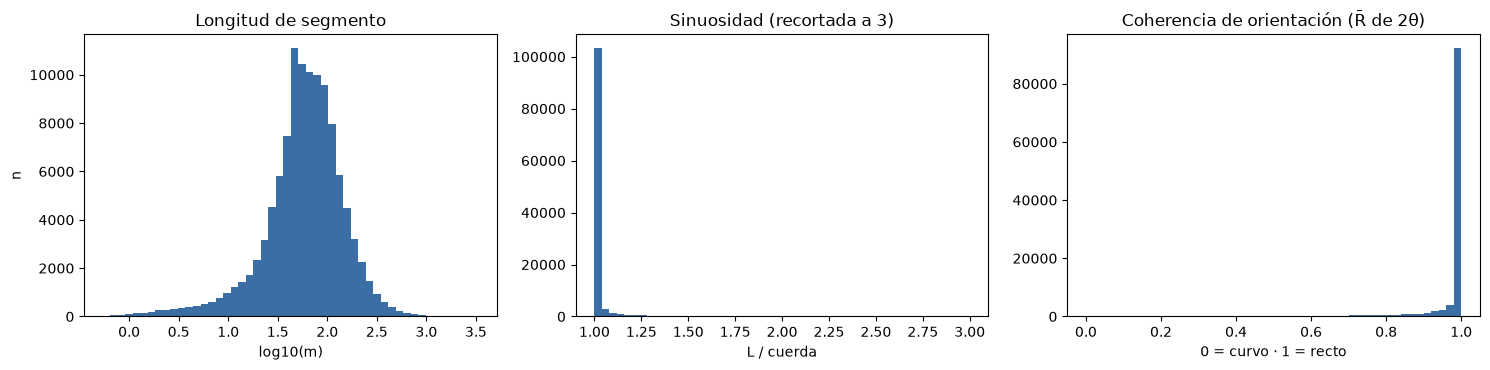

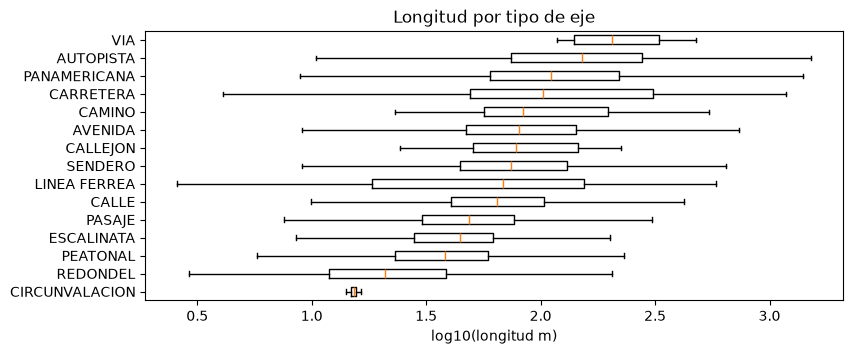

In [12]:
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
axs[0].hist(np.log10(ejes.eda_long_m.clip(lower=0.1)), bins=50, color="#3b6ea5")
axs[0].set(title="Longitud de segmento", xlabel="log10(m)", ylabel="n")
axs[1].hist(ejes.eda_sinuos.clip(upper=3).dropna(), bins=50, color="#3b6ea5")
axs[1].set(title="Sinuosidad (recortada a 3)", xlabel="L / cuerda")
axs[2].hist(ejes.eda_coher, bins=50, color="#3b6ea5")
axs[2].set(title="Coherencia de orientación (R̄ de 2θ)", xlabel="0 = curvo · 1 = recto")
plt.tight_layout(); plt.show()

if "tipo_eje" in ejes.columns:
    orden = ejes.groupby("tipo_eje").eda_long_m.median().sort_values().index
    fig, ax = plt.subplots(figsize=(9, 3.5))
    datos_bp = [np.log10(ejes.loc[ejes.tipo_eje == t, "eda_long_m"]) for t in orden]
    try:
        ax.boxplot(datos_bp, orientation="horizontal", showfliers=False)   # matplotlib >= 3.10
    except TypeError:
        ax.boxplot(datos_bp, vert=False, showfliers=False)
    ax.set_yticklabels(orden); ax.set(xlabel="log10(longitud m)", title="Longitud por tipo de eje"); plt.show()

## 8. Orientación de la red (forma)
- **Rosa de orientaciones** con rumbos recíprocos en 36 bins de 10° desplazados −5°, ponderada por longitud (Boeing, 2019).
- **Entropía de orientación** $H_o = -\sum_i P(o_i)\ln P(o_i)$ y **orden** $\varphi = 1 - \left(\frac{H_o - H_g}{H_{max} - H_g}\right)^2$ con $H_{max}=\ln 36$ y $H_g=\ln 4$ (cuadrícula perfecta): φ ≈ 1 cuadrícula, φ ≈ 0 desorden.
- **Componente N–S/E–O** $\bar C = \sum l_i\cos 2\theta_i / \sum l_i$: +1 si toda la longitud es N–S, −1 si es E–O. Es el término cos 2θ del tensor de orientación; responde directamente "¿predominan las calles N–S o E–O?".

Se comparan tres variantes: rumbo de la **cuerda** (comparable con Boeing/OSMnx), de los **sub-tramos** (captura curvas) y sin ponderar.

,H_o (nats),φ orden,az_medio,R,comp_NS_EO,comp_NE_NO
variante,,,,,,
"Cuerda, por longitud",3.540503,0.038771,16.387012,0.041583,0.034963,0.022510
"Sub-tramos, por longitud",3.537571,0.041386,15.995806,0.042664,0.036184,0.022603
"Cuerda, sin ponderar",3.533095,0.045371,22.458667,0.011080,0.007846,0.007824


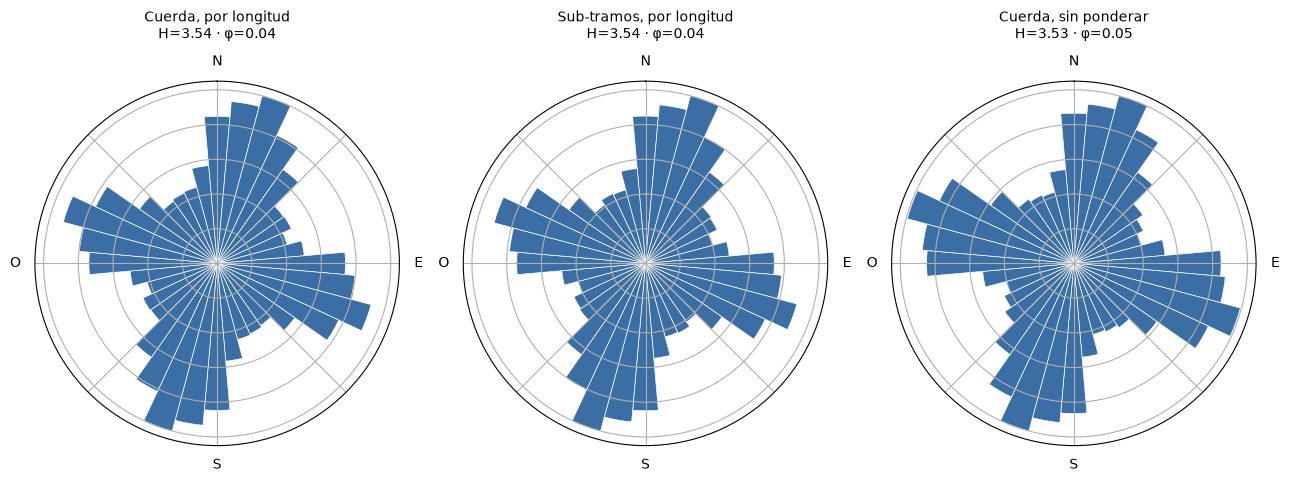

In [13]:
sl, th, *_ = subsegmentos(ejes.geometry.values)
az_sub = np.degrees(th) % 180

variantes = {
    "Cuerda, por longitud": (ejes.eda_az_cuerda, ejes.eda_long_m),
    "Sub-tramos, por longitud": (az_sub, sl),
    "Cuerda, sin ponderar": (ejes.eda_az_cuerda, None),
}
filas = []
for k, (a, w) in variantes.items():
    H, phi = entropia_orientacion(a, w)
    filas.append({"variante": k, "H_o (nats)": H, "φ orden": phi, **resumen_axial(a, w)})
tabla_or = pd.DataFrame(filas).set_index("variante")
display(tabla_or)

fig, axs = plt.subplots(1, 3, figsize=(13, 4.5), subplot_kw={"projection": "polar"})
for ax, (k, (a, w)) in zip(axs, variantes.items()):
    H, phi = entropia_orientacion(a, w)
    rosa(ax, a, w, titulo=f"{k}\nH={H:.2f} · φ={phi:.2f}")
plt.tight_layout(); plt.show()

In [14]:
# Participación de longitud por clase de orientación
part = ejes.groupby("eda_clase_or", observed=False).eda_long_m.sum()
part = (part / part.sum()).rename("pct_longitud").to_frame()
L_ns, L_eo = part.loc["N–S", "pct_longitud"], part.loc["E–O", "pct_longitud"]
print(f"Índice de anisotropía (L_NS − L_EO)/(L_NS + L_EO) = {(L_ns-L_eo)/(L_ns+L_eo):+.3f}")
part

Índice de anisotropía (L_NS − L_EO)/(L_NS + L_EO) = +0.063


,pct_longitud
eda_clase_or,
N–S,0.293532
NE–SO,0.234035
E–O,0.258556
NO–SE,0.213877


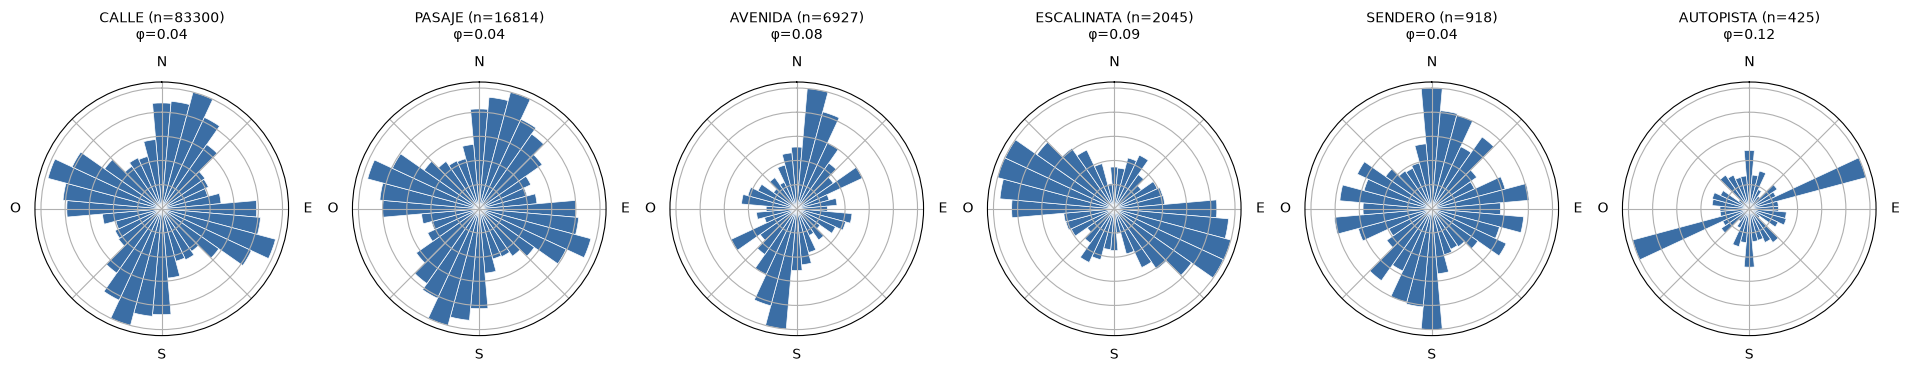

In [15]:
if "tipo_eje" in ejes.columns:
    tipos = ejes.groupby("tipo_eje").eda_long_m.sum().sort_values(ascending=False).index[:6]
    fig, axs = plt.subplots(1, len(tipos), figsize=(3.2*len(tipos), 3.6), subplot_kw={"projection": "polar"})
    for ax, t in zip(np.atleast_1d(axs), tipos):
        s = ejes[ejes.tipo_eje == t]
        H, phi = entropia_orientacion(s.eda_az_cuerda, s.eda_long_m)
        rosa(ax, s.eda_az_cuerda, s.eda_long_m, titulo=f"{t} (n={len(s)})\nφ={phi:.2f}")
    plt.tight_layout(); plt.show()

### 9. Mapas

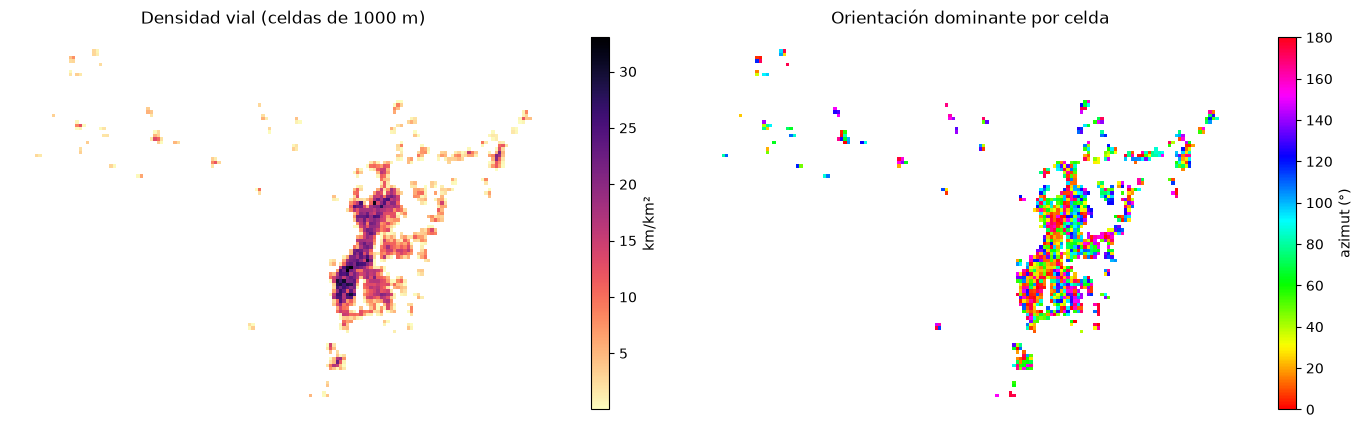

In [16]:
# Malla: densidad vial y orientación dominante por celda
ix = np.floor(ejes.eda_cx / TAM_CELDA).astype(np.int64)
iy = np.floor(ejes.eda_cy / TAM_CELDA).astype(np.int64)
celdas = (pd.DataFrame({"ix": ix, "iy": iy, "L": ejes.eda_long_m, "c2": ejes._c2, "s2": ejes._s2})
          .groupby(["ix", "iy"]).sum().reset_index())
celdas["dens_km_km2"] = (celdas.L / 1000) / (TAM_CELDA / 1000) ** 2
celdas["az_dom"] = (np.degrees(np.arctan2(celdas.s2, celdas.c2)) / 2) % 180
grilla = gpd.GeoDataFrame(celdas, crs=ejes.crs, geometry=shapely.box(
    celdas.ix * TAM_CELDA, celdas.iy * TAM_CELDA, (celdas.ix + 1) * TAM_CELDA, (celdas.iy + 1) * TAM_CELDA))

fig, axs = plt.subplots(1, 2, figsize=(14, 6.5))
grilla.plot("dens_km_km2", ax=axs[0], cmap="magma_r", legend=True, legend_kwds={"shrink": .6, "label": "km/km²"})
axs[0].set_title(f"Densidad vial (celdas de {TAM_CELDA} m)")
grilla.plot("az_dom", ax=axs[1], cmap=CMAP_AXIAL, vmin=0, vmax=180, legend=True, legend_kwds={"shrink": .6, "label": "azimut (°)"})
axs[1].set_title("Orientación dominante por celda")
for ax in axs: ax.set_axis_off()
plt.tight_layout(); plt.show()

## 10. Resumen por grupo

In [17]:
def resumen_grupo(s):
    H, phi = entropia_orientacion(s.eda_az_cuerda, s.eda_long_m)
    ax_ = resumen_axial(s.eda_az_cuerda, s.eda_long_m)
    return pd.Series({
        "n_segmentos": len(s), "long_km": s.eda_long_m.sum() / 1000,
        "H_o": H, "phi": phi, "az_medio_calles": ax_["az_medio"], "R": ax_["R"], "C_NS_EO": ax_["comp_NS_EO"],
        "sinuos_mediana": s.eda_sinuos.median(),
    })

grp = ejes.groupby(CAMPO_GRUPO).filter(lambda s: len(s) >= MIN_SEGMENTOS).groupby(CAMPO_GRUPO)
resumen = grp.apply(resumen_grupo, include_groups=False)
resumen.sort_values("long_km", ascending=False).head(20)

,n_segmentos,long_km,H_o,phi,az_medio_calles,R,C_NS_EO,sinuos_mediana
parroquia,,,,,,,,
170150,58214.0,4230.365041,3.541051,0.038282,15.398743,0.084017,0.072169,1.000000
170155,10521.0,782.709195,3.458100,0.110903,109.009407,0.038602,-0.030411,1.000000
170156,5753.0,486.962977,3.366774,0.187559,178.110710,0.058336,0.058209,1.000049
170550,4966.0,425.120723,3.458643,0.110437,143.734138,0.072930,0.021892,1.000020
170184,2546.0,284.820194,3.442286,0.124424,82.059561,0.067192,-0.064627,1.000268
170157,2104.0,231.133313,3.446583,0.120761,63.078904,0.100644,-0.059381,1.000590
170180,2228.0,207.814369,3.337903,0.211073,12.999152,0.029250,0.026290,1.000000
170152,1779.0,175.252748,3.343608,0.206454,49.454485,0.040841,-0.006325,1.000015
170353,1837.0,166.890010,3.326236,0.220478,15.632875,0.129911,0.111044,1.000000


### 11. Conclusiones
Para hablar de crecimiento, es necesario contar con información de al menos dos temporalidades distintas. Por lo que no es posible hablar de este factor con los datos analizados.

Con el conjunto de datos utilizado, sí se puede verificar la forma de la ciudad con otra perspectiva. Sobre el filtro de la provincia, destacan los registros para Quito, considerando que casi 52% corresponden la capital.